# Surgical Tool Detection — YOLO11m


## 1. Environment check

In [1]:
!nvidia-smi

Thu Jul 23 11:05:37 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   39C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
!pip install -q ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.3/45.3 kB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 36.4 MB/s eta 0:00:00


In [3]:
import ultralytics
from ultralytics import YOLO
import torch

print("Ultralytics Version:", ultralytics.__version__)
print("Torch Version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

# Hard stop if there's no GPU -- training on CPU here will silently "work"
# but take ~50-100x longer and is almost certainly not what you want.
assert torch.cuda.is_available(), (
    "No GPU visible to this runtime. Go to Runtime > Change runtime type > "
    "select 'T4 GPU', then Runtime > Restart session, then re-run from the top."
)

DEVICE = 0
print("Using device:", DEVICE)

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
Ultralytics Version: 8.4.104
Torch Version: 2.11.0+cu128
CUDA available: True
Using device: 0


## 2. Mount Drive and locate the dataset zip

In [4]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [8]:
import os

project_path = "/content/drive/MyDrive"

print("Drive Mounted:", os.path.exists(project_path))
print("\nFolders/files in MyDrive:\n")

for f in sorted(os.listdir(project_path)):
    print(f)

Drive Mounted: True

Folders/files in MyDrive:

Colab Notebooks
Tools.yolo26.zip
surgical_yolo_results
surgical_yolo_results.zip


In [6]:
import glob as _glob
import os

# Auto-detect the dataset zip instead of hardcoding an exact filename
# (Drive appends " (1)", " (2)", etc. to duplicate uploads, so the exact
# name will differ between accounts/runs).
candidates = _glob.glob("/content/drive/MyDrive/Tools.yolo26*.zip")

if not candidates:
    raise FileNotFoundError(
        "No file matching 'Tools.yolo26*.zip' found in /content/drive/MyDrive. "
        "Upload the dataset zip to Drive first, or update the glob pattern below "
        "to match its actual name."
    )

# If there are duplicates, prefer the most recently modified one
candidates.sort(key=os.path.getmtime, reverse=True)
drive_zip = candidates[0]

if len(candidates) > 1:
    print(f"Warning: multiple matches found, using the most recent: {drive_zip}")
    print("All matches:", candidates)
else:
    print("Found dataset zip:", drive_zip)

Found dataset zip: /content/drive/MyDrive/Tools.yolo26.zip


In [9]:
import shutil
import os

local_zip = "/content/Tools.yolo26.zip"

shutil.copy(drive_zip, local_zip)

print("Copied:", os.path.exists(local_zip))

Copied: True


In [10]:
import zipfile
import os

extract_path = "/content/dataset"

with zipfile.ZipFile(local_zip, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Extraction Completed!")

Extraction Completed!


## 3. Dataset sanity checks

In [11]:
import os

for root, dirs, files in os.walk("/content/dataset"):
    print(root)

/content/dataset
/content/dataset/valid
/content/dataset/valid/labels
/content/dataset/valid/images
/content/dataset/train
/content/dataset/train/labels
/content/dataset/train/images
/content/dataset/test
/content/dataset/test/labels
/content/dataset/test/images


In [12]:
import os

yaml_files = []

for root, dirs, files in os.walk("/content/dataset"):
    for file in files:
        if file.endswith(".yaml"):
            yaml_files.append(os.path.join(root, file))

print(yaml_files)

assert yaml_files, "No data.yaml found inside the extracted dataset -- check the zip contents."

['/content/dataset/data.yaml']


In [13]:
yaml_path = "/content/dataset/data.yaml"

assert os.path.exists(yaml_path), f"{yaml_path} not found -- check the extracted folder structure above."

with open(yaml_path, "r") as f:
    print(f.read())

train: ../train/images
val: ../valid/images
test: ../test/images

nc: 5
names: ['Bipolar', 'Grasper', 'Hook', 'Irrigator', 'Scissors']

roboflow:
  workspace: sameerdeshpande-17-gmail-com
  project: tools-snfsg
  version: dataset
  license: CC BY 4.0
  url: https://universe.roboflow.com/sameerdeshpande-17-gmail-com/tools-snfsg/dataset/dataset


In [14]:
from glob import glob

train_images = len(glob("/content/dataset/train/images/*"))
train_labels = len(glob("/content/dataset/train/labels/*"))

valid_images = len(glob("/content/dataset/valid/images/*"))
valid_labels = len(glob("/content/dataset/valid/labels/*"))

test_images = len(glob("/content/dataset/test/images/*"))
test_labels = len(glob("/content/dataset/test/labels/*"))

print(f"Train Images : {train_images}")
print(f"Train Labels : {train_labels}")

print(f"Validation Images : {valid_images}")
print(f"Validation Labels : {valid_labels}")

print(f"Test Images : {test_images}")
print(f"Test Labels : {test_labels}")

assert train_images > 0, "No training images found -- check the dataset extraction."

Train Images : 1740
Train Labels : 1740
Validation Images : 370
Validation Labels : 370
Test Images : 227
Test Labels : 227


In [15]:
from pathlib import Path

image_extensions = {'.jpg', '.jpeg', '.png'}

image_dir = Path("/content/dataset/train/images")
label_dir = Path("/content/dataset/train/labels")

missing_labels = []

for image in image_dir.iterdir():
    if image.suffix.lower() in image_extensions:
        label = label_dir / (image.stem + ".txt")
        if not label.exists():
            missing_labels.append(image.name)

print("Missing Labels:", len(missing_labels))

if len(missing_labels) > 0:
    print(missing_labels[:20])

Missing Labels: 0


In [16]:
from pathlib import Path

label_dir = Path("/content/dataset/train/labels")

empty = []

for file in label_dir.glob("*.txt"):
    if file.stat().st_size == 0:
        empty.append(file.name)

print("Empty Labels:", len(empty))

if len(empty):
    print(empty[:20])

Empty Labels: 0


In [17]:
from pathlib import Path

invalid = []

for file in Path("/content/dataset/train/labels").glob("*.txt"):
    with open(file) as f:
        for line in f:
            values = line.strip().split()
            if len(values) == 0:
                continue
            cls = int(float(values[0]))
            if cls not in [0, 1, 2, 3, 4]:
                invalid.append((file.name, cls))

print("Invalid Class IDs:", len(invalid))

if invalid:
    print(invalid[:10])

Invalid Class IDs: 0


In [18]:
from collections import Counter
from pathlib import Path

CLASS_NAMES = {
    0: "Bipolar",
    1: "Grasper",
    2: "Hook",
    3: "Irrigator",
    4: "Scissors",
}

counter = Counter()

for file in Path("/content/dataset/train/labels").glob("*.txt"):
    with open(file) as f:
        for line in f:
            values = line.strip().split()
            if len(values):
                counter[int(values[0])] += 1

print(counter)
print()

for i in range(5):
    print(f"{CLASS_NAMES[i]:10}: {counter[i]}")

Counter({1: 1055, 0: 352, 3: 346, 4: 293, 2: 232})

Bipolar   : 352
Grasper   : 1055
Hook      : 232
Irrigator : 346
Scissors  : 293


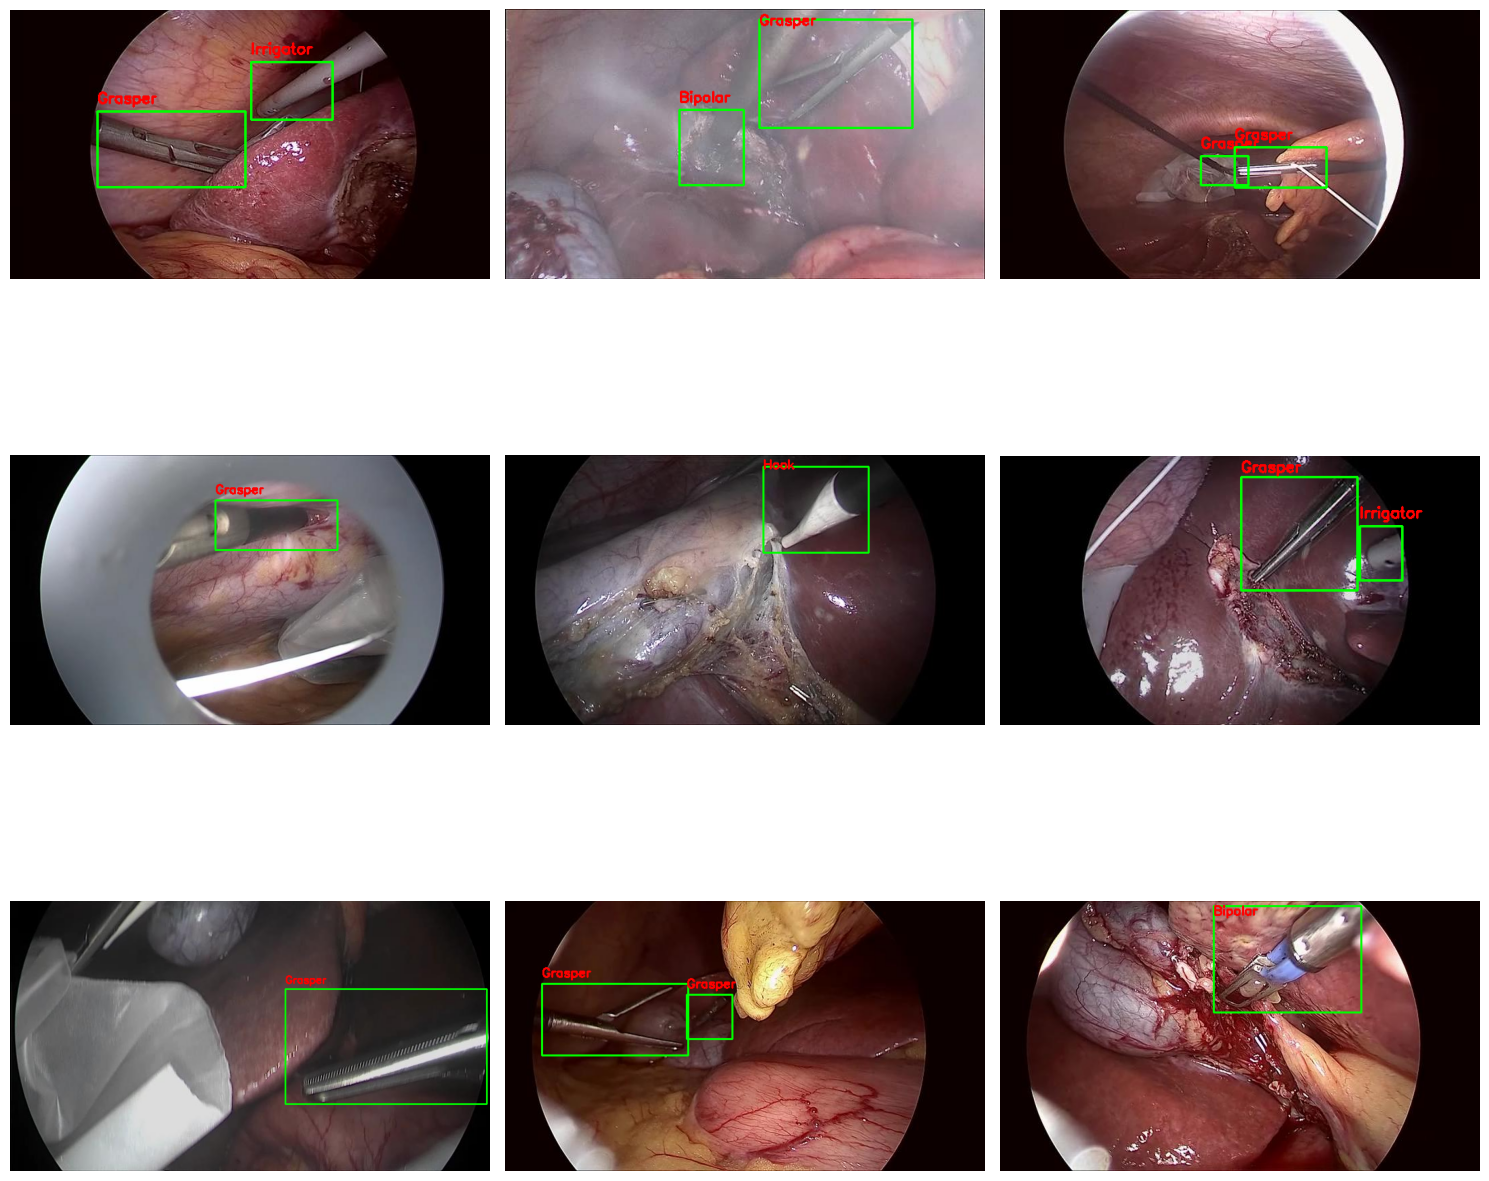

In [19]:
import cv2
import random
import matplotlib.pyplot as plt
from pathlib import Path

image_dir = Path("/content/dataset/train/images")
label_dir = Path("/content/dataset/train/labels")

class_names = ['Bipolar', 'Grasper', 'Hook', 'Irrigator', 'Scissors']

images = random.sample(list(image_dir.glob("*")), 9)

plt.figure(figsize=(15, 15))

for i, image_path in enumerate(images):
    img = cv2.imread(str(image_path))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    h, w = img.shape[:2]

    label_path = label_dir / (image_path.stem + ".txt")

    if label_path.exists():
        with open(label_path) as f:
            for line in f:
                cls, x, y, bw, bh = map(float, line.split())

                x1 = int((x - bw / 2) * w)
                y1 = int((y - bh / 2) * h)
                x2 = int((x + bw / 2) * w)
                y2 = int((y + bh / 2) * h)

                cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), 2)

                cv2.putText(
                    img,
                    class_names[int(cls)],
                    (x1, max(y1 - 10, 20)),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    0.6,
                    (255, 0, 0),
                    2,
                )

    plt.subplot(3, 3, i + 1)
    plt.imshow(img)
    plt.axis("off")

plt.tight_layout()
plt.show()

## 4. Baseline training (YOLO11m on the unbalanced dataset)

In [20]:
DRIVE_RESULTS_DIR = "/content/drive/MyDrive/surgical_yolo_results"

model = YOLO("yolo11m.pt")

In [ ]:
results = model.train(
    data="/content/dataset/data.yaml",

    epochs=100,
    imgsz=640,
    batch=16,

    optimizer="AdamW",
    lr0=0.001,
    weight_decay=0.0005,

    patience=20,
    cos_lr=True,

    workers=2,
    cache=True,

    amp=True,
    device=DEVICE,

    project=DRIVE_RESULTS_DIR,
    name="YOLO11m_baseline",

    exist_ok=True,
    verbose=True,
    plots=True,
    seed=42,
)

Ultralytics 8.4.104 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=True, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11m.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=YOLO11m_baseline, nbs=64, nms=False, opset=None, optimiz

In [ ]:
import os

result_dir = f"{DRIVE_RESULTS_DIR}/YOLO11m_baseline"

print("Files generated:\n")

for file in sorted(os.listdir(result_dir)):
    print(file)

Files generated:

BoxF1_curve.png
BoxPR_curve.png
BoxP_curve.png
BoxR_curve.png
args.yaml
confusion_matrix.png
confusion_matrix_normalized.png
labels.jpg
results.csv
results.png
train_batch0.jpg
train_batch1.jpg
train_batch2.jpg
train_batch9810.jpg
train_batch9811.jpg
train_batch9812.jpg
val_batch0_labels.jpg
val_batch0_pred.jpg
val_batch1_labels.jpg
val_batch1_pred.jpg
val_batch2_labels.jpg
val_batch2_pred.jpg
weights


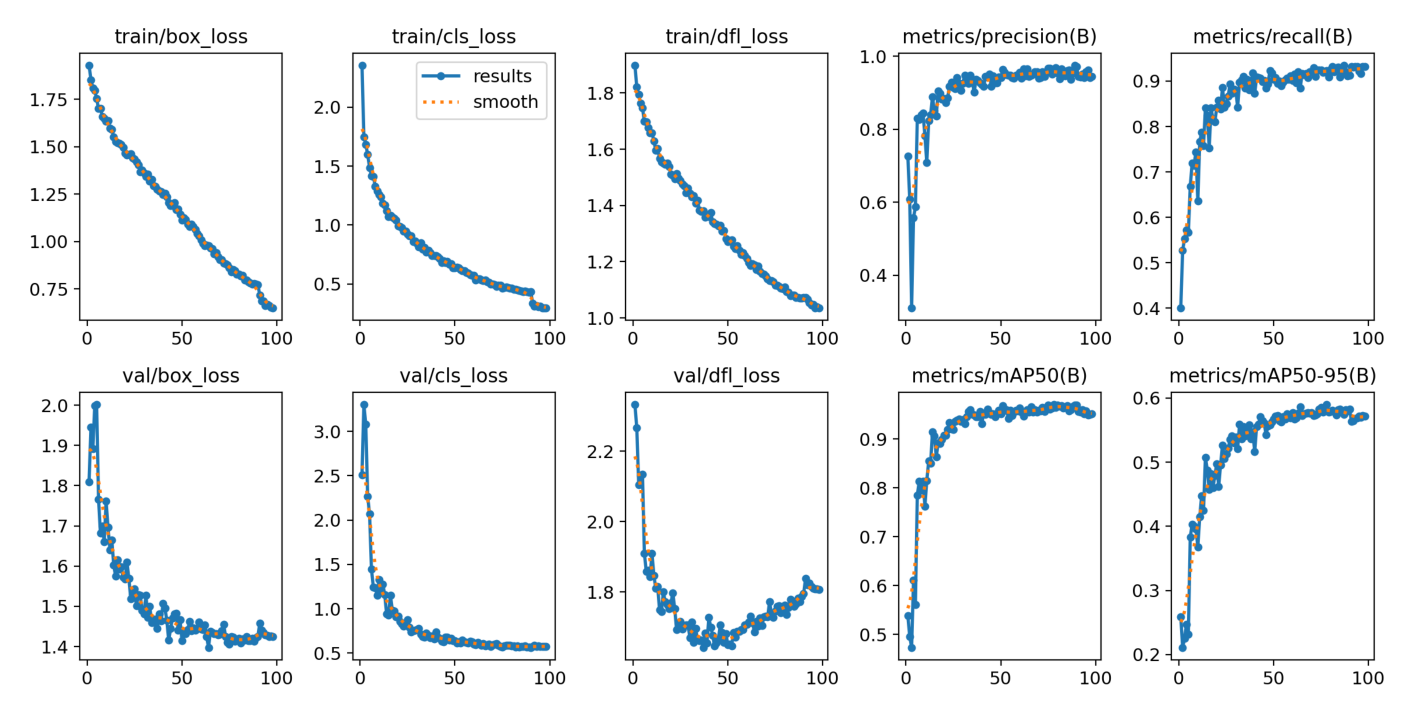

In [21]:
from PIL import Image
import matplotlib.pyplot as plt

img = Image.open(f"{DRIVE_RESULTS_DIR}/YOLO11m_baseline/results.png")

plt.figure(figsize=(18, 10))
plt.imshow(img)
plt.axis('off')
plt.show()

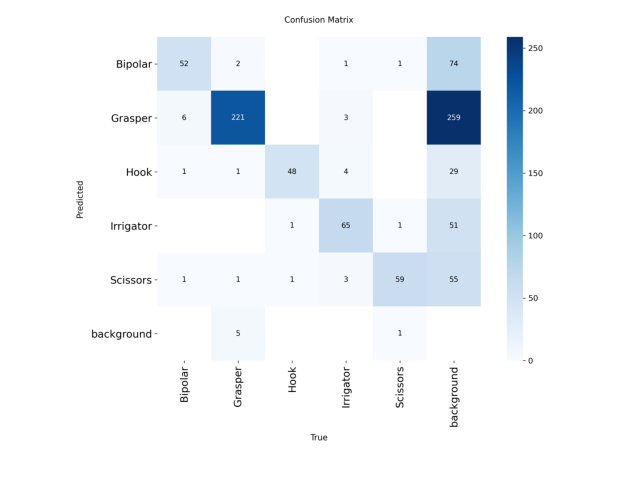

In [22]:
img = Image.open(f"{DRIVE_RESULTS_DIR}/YOLO11m_baseline/confusion_matrix.png")

plt.figure(figsize=(8, 8))
plt.imshow(img)
plt.axis('off')
plt.show()

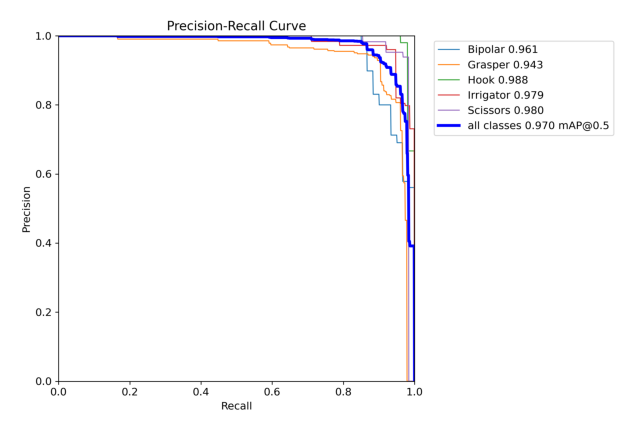

In [23]:
img = Image.open(f"{DRIVE_RESULTS_DIR}/YOLO11m_baseline/BoxPR_curve.png")

plt.figure(figsize=(8, 8))
plt.imshow(img)
plt.axis('off')
plt.show()

In [24]:
baseline_model = YOLO(f"{DRIVE_RESULTS_DIR}/YOLO11m_baseline/weights/best.pt")

metrics = baseline_model.val(
    data="/content/dataset/data.yaml",
    split="test",
    imgsz=640,
    batch=16,
    device=DEVICE,
    plots=True,
)

print(metrics)

Ultralytics 8.4.104 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLO11m summary (fused): 126 layers, 20,033,887 parameters, 0 gradients, 67.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 974.7±459.4 MB/s, size: 31.5 KB)
val: Scanning /content/dataset/test/labels... 227 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 227/227 2.4Kit/s 0.1s
val: New cache created: /content/dataset/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 15/15 2.4it/s 6.3s
                   all        227        297      0.931       0.95       0.96      0.583
               Bipolar         38         38       0.97          1      0.994      0.567
               Grasper        108        137        0.9      0.847       0.91      0.525
                  Hook         26         26      0.895          1      0.992      0.737
             Irrigator         63         63      0.967      0.932      0.951     

In [25]:
pred_results = baseline_model.predict(
    source="/content/dataset/test/images",
    imgsz=640,
    conf=0.25,
    save=True,
    save_txt=True,
    line_width=3,
)


image 1/227 /content/dataset/test/images/v01_025800_jpg.rf.QgIDbmcPG85rD7z21uib.jpg: 384x640 1 Grasper, 51.4ms
image 2/227 /content/dataset/test/images/v01_027675_jpg.rf.AWxUlbySBV0sCDUpngwY.jpg: 384x640 2 Graspers, 1 Scissors, 23.9ms
image 3/227 /content/dataset/test/images/v01_027925_jpg.rf.LtNDuMjSVCTxZNDM5VMO.jpg: 384x640 2 Graspers, 1 Scissors, 23.9ms
image 4/227 /content/dataset/test/images/v01_028150_jpg.rf.WXl0CTYuEYuDs9StOUV4.jpg: 384x640 2 Graspers, 1 Scissors, 23.9ms
image 5/227 /content/dataset/test/images/v01_028500_jpg.rf.HcXOz1jVQ1pvbDGjyrOR.jpg: 384x640 2 Graspers, 1 Scissors, 23.9ms
image 6/227 /content/dataset/test/images/v01_052475_jpg.rf.A3WpdLlwPOGbxpe2v6HM.jpg: 384x640 1 Grasper, 23.9ms
image 7/227 /content/dataset/test/images/v01_054100_jpg.rf.5qFTdLfuAF31ZiZBstak.jpg: 384x640 1 Grasper, 23.8ms
image 8/227 /content/dataset/test/images/v01_054600_jpg.rf.gArAldheiqJkufLepBxK.jpg: 384x640 2 Graspers, 23.8ms
image 9/227 /content/dataset/test/images/v01_054975_jpg.rf

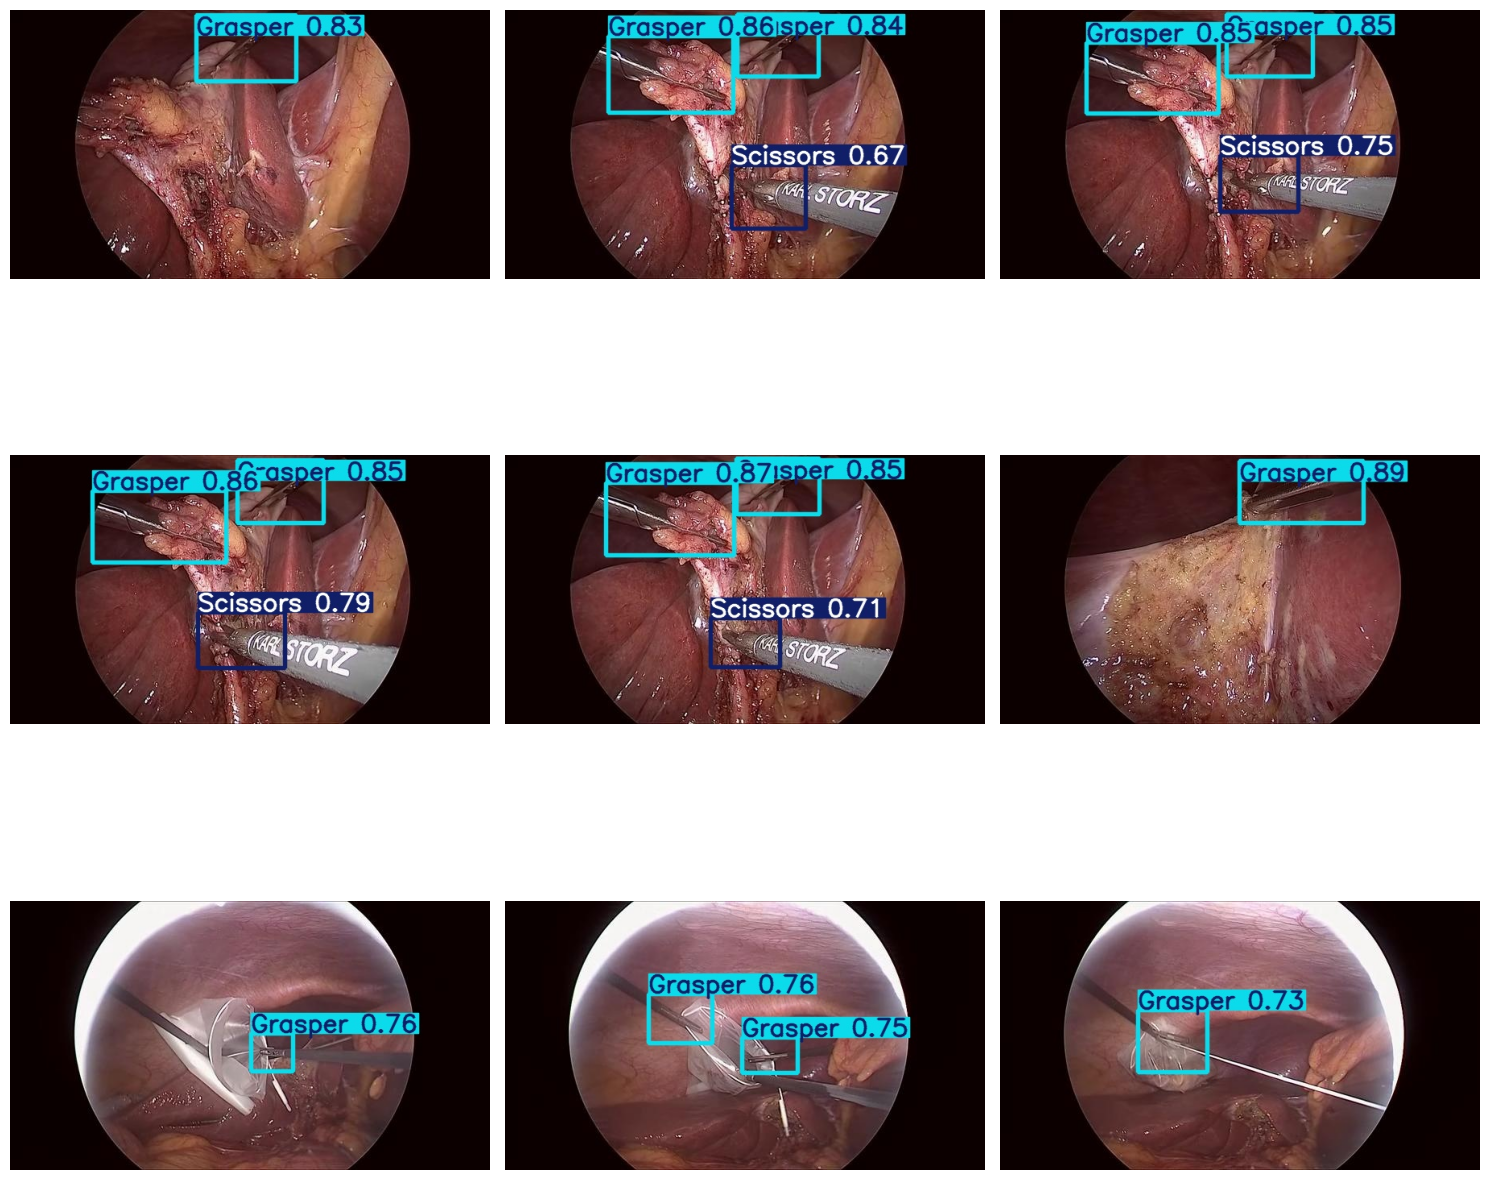

In [26]:
from glob import glob
import matplotlib.pyplot as plt
from PIL import Image

predictions = sorted(glob("/content/runs/detect/predict/*.jpg"))[:9]

plt.figure(figsize=(15, 15))

for i, img_path in enumerate(predictions):
    img = Image.open(img_path)
    plt.subplot(3, 3, i + 1)
    plt.imshow(img)
    plt.axis("off")

plt.tight_layout()
plt.show()

## 5. Rebalance the dataset

Builds a fresh copy of the dataset, then augments the minority classes up to the
majority class's count using Albumentations, writing new image/label pairs directly
into `dataset_balanced/train`.

In [27]:
import shutil
from pathlib import Path

# Clean slate: remove any previous balanced dataset / training runs so this
# cell is safe to re-run from scratch.
for folder in ["/content/dataset_balanced", "/content/runs"]:
    folder = Path(folder)
    if folder.exists():
        shutil.rmtree(folder)
        print(f"Deleted {folder}")

print("Done.")

Deleted /content/runs
Done.


In [28]:
import shutil

assert os.path.exists("/content/dataset"), "/content/dataset is missing -- re-run the extraction cells above."

shutil.copytree("/content/dataset", "/content/dataset_balanced")

print("Fresh dataset_balanced created.")

Fresh dataset_balanced created.


In [29]:
from pathlib import Path
from collections import defaultdict

dataset = Path("/content/dataset_balanced/train")

class_to_images = defaultdict(list)
single_class_images = defaultdict(list)
multi_class_images = defaultdict(list)

label_files = sorted((dataset / "labels").glob("*.txt"))

for lbl_path in label_files:
    img_path = dataset / "images" / (lbl_path.stem + ".jpg")
    if not img_path.exists():
        img_path = dataset / "images" / (lbl_path.stem + ".png")
    if not img_path.exists():
        continue

    with open(lbl_path) as f:
        lines = [x.strip() for x in f if x.strip()]

    classes = [int(float(line.split()[0])) for line in lines]
    unique_classes = set(classes)

    for cls in unique_classes:
        class_to_images[cls].append((img_path, lbl_path))
        if len(unique_classes) == 1:
            single_class_images[cls].append((img_path, lbl_path))
        else:
            multi_class_images[cls].append((img_path, lbl_path))

print("=" * 50)
for cls in range(5):
    print(
        f"{CLASS_NAMES[cls]:10}"
        f" Total={len(class_to_images[cls]):4}"
        f" | Single={len(single_class_images[cls]):4}"
        f" | Multi={len(multi_class_images[cls]):4}"
    )

Bipolar    Total= 352 | Single= 185 | Multi= 167
Grasper    Total= 848 | Single= 517 | Multi= 331
Hook       Total= 232 | Single= 231 | Multi=   1
Irrigator  Total= 346 | Single= 272 | Multi=  74
Scissors   Total= 293 | Single= 204 | Multi=  89


In [30]:
!pip install -q albumentations opencv-python-headless

In [31]:
import albumentations as A

transform = A.Compose(
    [
        A.HorizontalFlip(p=0.5),
        A.RandomBrightnessContrast(
            brightness_limit=0.2,
            contrast_limit=0.2,
            p=0.5,
        ),
        A.Rotate(limit=15, border_mode=0, p=0.5),
        A.Affine(
            scale=(0.9, 1.1),
            translate_percent=(-0.05, 0.05),
            rotate=(-10, 10),
            shear=(-5, 5),
            p=0.5,
        ),
        A.GaussNoise(std_range=(0.02, 0.08), p=0.3),
        A.CLAHE(p=0.3),
    ],
    bbox_params=A.BboxParams(
        format="yolo",
        label_fields=["class_labels"],
        min_visibility=0.3,
    ),
)

print("Augmentation pipeline ready.")

Augmentation pipeline ready.


In [32]:
# These two were previously MISSING -- cell 35 in the old notebook called them
# without ever defining them, which is why the balancing step silently failed
# and dataset_balanced/data.yaml never got created.

def load_yolo_labels(lbl_path):
    """Read a YOLO-format label file -> (bboxes, class_labels)."""
    bboxes, labels = [], []
    with open(lbl_path) as f:
        for line in f:
            line = line.strip()
            if not line:
                continue
            parts = line.split()
            cls = int(float(parts[0]))
            x, y, w, h = map(float, parts[1:5])
            bboxes.append([x, y, w, h])
            labels.append(cls)
    return bboxes, labels


def save_yolo_labels(lbl_path, bboxes, class_labels):
    """Write (bboxes, class_labels) back out in YOLO-format."""
    with open(lbl_path, "w") as f:
        for bbox, cls in zip(bboxes, class_labels):
            x, y, w, h = bbox
            f.write(f"{int(cls)} {x:.6f} {y:.6f} {w:.6f} {h:.6f}\n")


print("load_yolo_labels" in globals(), "save_yolo_labels" in globals())

True True


In [33]:
from pathlib import Path
import uuid

image_dir = Path("/content/dataset_balanced/train/images")


def unique_name():
    while True:
        name = "aug_" + uuid.uuid4().hex[:12]
        if not (image_dir / f"{name}.jpg").exists():
            return name

In [34]:
from collections import Counter
from pathlib import Path

train_labels = Path("/content/dataset_balanced/train/labels")

current_counts = Counter()

for lbl in train_labels.glob("*.txt"):
    with open(lbl) as f:
        for line in f:
            if line.strip():
                cls = int(float(line.split()[0]))
                current_counts[cls] += 1

# Derived from the data instead of hardcoded, so this stays correct even if
# the dataset composition changes on a re-export.
TARGET = max(current_counts.values())

print("Current counts:")
for i in range(5):
    print(f"{CLASS_NAMES[i]:10}: {current_counts[i]}")

print("\nTarget per class:", TARGET)

Current counts:
Bipolar   : 352
Grasper   : 1055
Hook      : 232
Irrigator : 346
Scissors  : 293

Target per class: 1055


In [35]:
import cv2
import random
from pathlib import Path

image_dir = Path("/content/dataset_balanced/train/images")
label_dir = Path("/content/dataset_balanced/train/labels")

generated = 0

# Iterate all 5 classes -- any class already at/above TARGET (e.g. the
# majority class) is skipped automatically by the while condition, so there's
# no need to hardcode which classes need balancing.
for cls in range(5):
    if current_counts[cls] >= TARGET:
        continue

    if not single_class_images[cls]:
        print(f"Skipping {CLASS_NAMES[cls]}: no single-class source images to augment from.")
        continue

    print(f"\nBalancing {CLASS_NAMES[cls]}")

    while current_counts[cls] < TARGET:
        img_path, lbl_path = random.choice(single_class_images[cls])

        image = cv2.imread(str(img_path))
        bboxes, labels = load_yolo_labels(lbl_path)

        aug = transform(image=image, bboxes=bboxes, class_labels=labels)

        if len(aug["bboxes"]) == 0:
            continue

        new_name = unique_name()

        cv2.imwrite(str(image_dir / f"{new_name}.jpg"), aug["image"])
        save_yolo_labels(label_dir / f"{new_name}.txt", aug["bboxes"], aug["class_labels"])

        for c in aug["class_labels"]:
            current_counts[int(c)] += 1

        generated += 1
        if generated % 100 == 0:
            print(f"Generated {generated} images")

print("\nFinished!")
print(f"Generated images: {generated}")

print("\nCurrent counts:")
for i in range(5):
    print(f"{CLASS_NAMES[i]:10}: {current_counts[i]}")


Balancing Bipolar
Generated 100 images
Generated 200 images
Generated 300 images
Generated 400 images
Generated 500 images
Generated 600 images
Generated 700 images

Balancing Hook
Generated 800 images
Generated 900 images
Generated 1000 images
Generated 1100 images
Generated 1200 images
Generated 1300 images
Generated 1400 images
Generated 1500 images

Balancing Irrigator
Generated 1600 images
Generated 1700 images
Generated 1800 images
Generated 1900 images
Generated 2000 images
Generated 2100 images
Generated 2200 images

Balancing Scissors
Generated 2300 images
Generated 2400 images
Generated 2500 images
Generated 2600 images
Generated 2700 images
Generated 2800 images
Generated 2900 images

Finished!
Generated images: 2997

Current counts:
Bipolar   : 1055
Grasper   : 1055
Hook      : 1055
Irrigator : 1055
Scissors  : 1055


In [36]:
from pathlib import Path
from collections import Counter

train_labels = Path("/content/dataset_balanced/train/labels")

counts = Counter()

for lbl in train_labels.glob("*.txt"):
    with open(lbl) as f:
        for line in f:
            if line.strip():
                cls = int(float(line.split()[0]))
                counts[cls] += 1

print("\nVerified counts from label files:")
for i in range(5):
    print(f"{CLASS_NAMES[i]:10}: {counts[i]}")

assert os.path.exists("/content/dataset_balanced/data.yaml"), (
    "dataset_balanced/data.yaml is missing -- the copytree step above should have "
    "carried it over from /content/dataset. Re-run the 'Fresh dataset_balanced created' cell."
)


Verified counts from label files:
Bipolar   : 1055
Grasper   : 1055
Hook      : 1055
Irrigator : 1055
Scissors  : 1055


## 6. Train on the balanced dataset

In [37]:
balanced_model = YOLO("yolo11m.pt")

results = balanced_model.train(
    data="/content/dataset_balanced/data.yaml",

    epochs=100,
    imgsz=640,
    batch=16,

    optimizer="AdamW",
    lr0=0.001,

    weight_decay=0.0005,
    cos_lr=True,

    hsv_h=0.015,
    hsv_s=0.7,
    hsv_v=0.4,

    degrees=10,
    translate=0.05,
    scale=0.3,
    shear=2,

    fliplr=0.5,
    mosaic=0.5,
    mixup=0.1,

    cache=True,
    workers=2,
    patience=20,
    device=DEVICE,

    project=DRIVE_RESULTS_DIR,
    name="YOLO11m_Balanced",

    exist_ok=True,
    verbose=True,
    plots=True,
    seed=42,
)

Ultralytics 8.4.104 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=True, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/dataset_balanced/data.yaml, degrees=10, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.1, mode=train, model=yolo11m.pt, momentum=0.937, mosaic=0.5, multi_scale=0.0, name=YOLO11m_Balanced, nbs=64, nms=False, opset=None,

In [38]:
import os

balanced_result_dir = f"{DRIVE_RESULTS_DIR}/YOLO11m_Balanced"

print("Files generated:\n")

for file in sorted(os.listdir(balanced_result_dir)):
    print(file)

Files generated:

BoxF1_curve.png
BoxPR_curve.png
BoxP_curve.png
BoxR_curve.png
args.yaml
confusion_matrix.png
confusion_matrix_normalized.png
labels.jpg
results.csv
results.png
train_batch0.jpg
train_batch1.jpg
train_batch2.jpg
val_batch0_labels.jpg
val_batch0_pred.jpg
val_batch1_labels.jpg
val_batch1_pred.jpg
val_batch2_labels.jpg
val_batch2_pred.jpg
weights


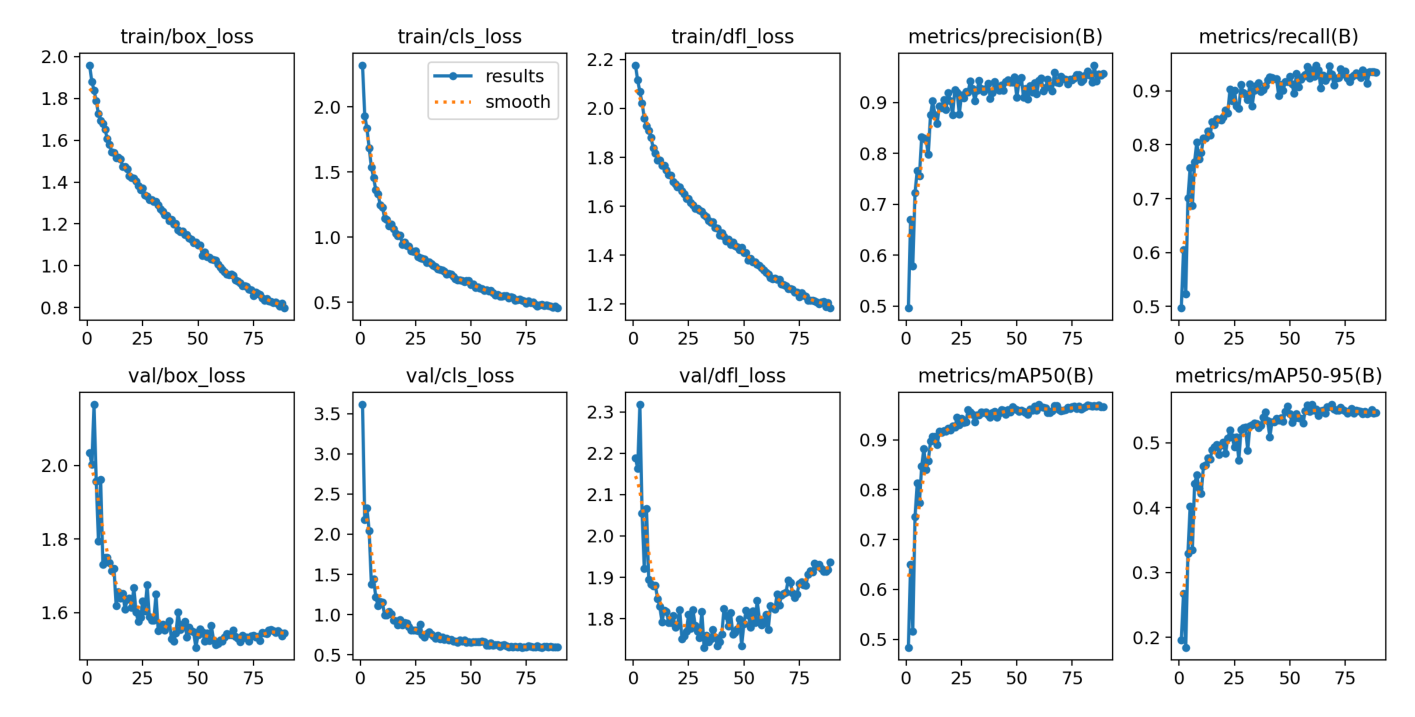

In [39]:
from PIL import Image
import matplotlib.pyplot as plt

img = Image.open(f"{DRIVE_RESULTS_DIR}/YOLO11m_Balanced/results.png")

plt.figure(figsize=(18, 10))
plt.imshow(img)
plt.axis('off')
plt.show()

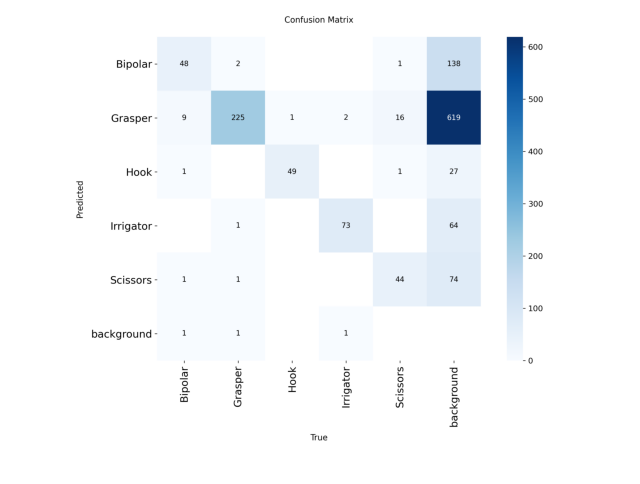

In [40]:
img = Image.open(f"{DRIVE_RESULTS_DIR}/YOLO11m_Balanced/confusion_matrix.png")

plt.figure(figsize=(8, 8))
plt.imshow(img)
plt.axis('off')
plt.show()

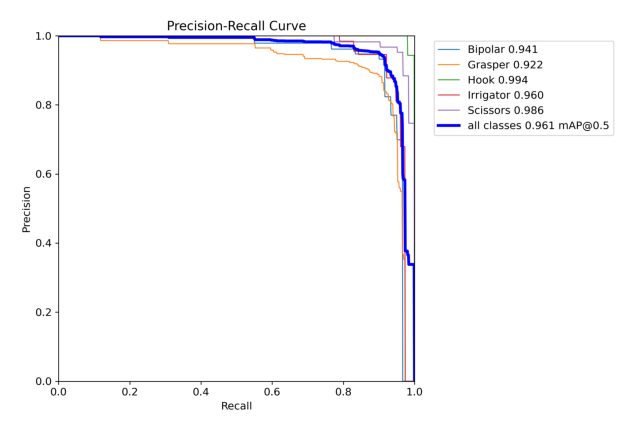

In [41]:
img = Image.open(f"{DRIVE_RESULTS_DIR}/YOLO11m_Balanced/BoxPR_curve.png")

plt.figure(figsize=(8, 8))
plt.imshow(img)
plt.axis('off')
plt.show()

In [42]:
balanced_model_best = YOLO(f"{DRIVE_RESULTS_DIR}/YOLO11m_Balanced/weights/best.pt")

metrics_balanced = balanced_model_best.val(
    data="/content/dataset_balanced/data.yaml",
    split="test",
    imgsz=640,
    batch=16,
    device=DEVICE,
    plots=True,
)

print(metrics_balanced)

Ultralytics 8.4.104 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLO11m summary (fused): 126 layers, 20,033,887 parameters, 0 gradients, 67.7 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.0±0.0 ms, read: 18.4±9.7 MB/s, size: 31.8 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips/
val: Scanning /content/dataset_balanced/test/labels... 227 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 227/227 664.6it/s 0.3s
val: New cache created: /content/dataset_balanced/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 15/15 2.3it/s 6.4s
                   all        227        297      0.922      0.916      0.945      0.576
               Bipolar         38         38       0.93      0.895      0.953      0.581
               Grasper        108        137      0.843      0.869      0.903      0.534

In [43]:
pred_results_balanced = balanced_model_best.predict(
    source="/content/dataset_balanced/test/images",
    imgsz=640,
    conf=0.25,
    save=True,
    save_txt=True,
    line_width=3,
    project="/content/runs/detect",
    name="predict_balanced",
)


image 1/227 /content/dataset_balanced/test/images/v01_025800_jpg.rf.QgIDbmcPG85rD7z21uib.jpg: 384x640 2 Graspers, 24.7ms
image 2/227 /content/dataset_balanced/test/images/v01_027675_jpg.rf.AWxUlbySBV0sCDUpngwY.jpg: 384x640 2 Graspers, 1 Scissors, 24.0ms
image 3/227 /content/dataset_balanced/test/images/v01_027925_jpg.rf.LtNDuMjSVCTxZNDM5VMO.jpg: 384x640 2 Graspers, 1 Scissors, 23.2ms
image 4/227 /content/dataset_balanced/test/images/v01_028150_jpg.rf.WXl0CTYuEYuDs9StOUV4.jpg: 384x640 2 Graspers, 1 Scissors, 19.1ms
image 5/227 /content/dataset_balanced/test/images/v01_028500_jpg.rf.HcXOz1jVQ1pvbDGjyrOR.jpg: 384x640 2 Graspers, 1 Scissors, 19.1ms
image 6/227 /content/dataset_balanced/test/images/v01_052475_jpg.rf.A3WpdLlwPOGbxpe2v6HM.jpg: 384x640 1 Grasper, 19.1ms
image 7/227 /content/dataset_balanced/test/images/v01_054100_jpg.rf.5qFTdLfuAF31ZiZBstak.jpg: 384x640 1 Grasper, 19.1ms
image 8/227 /content/dataset_balanced/test/images/v01_054600_jpg.rf.gArAldheiqJkufLepBxK.jpg: 384x640 2 Gr

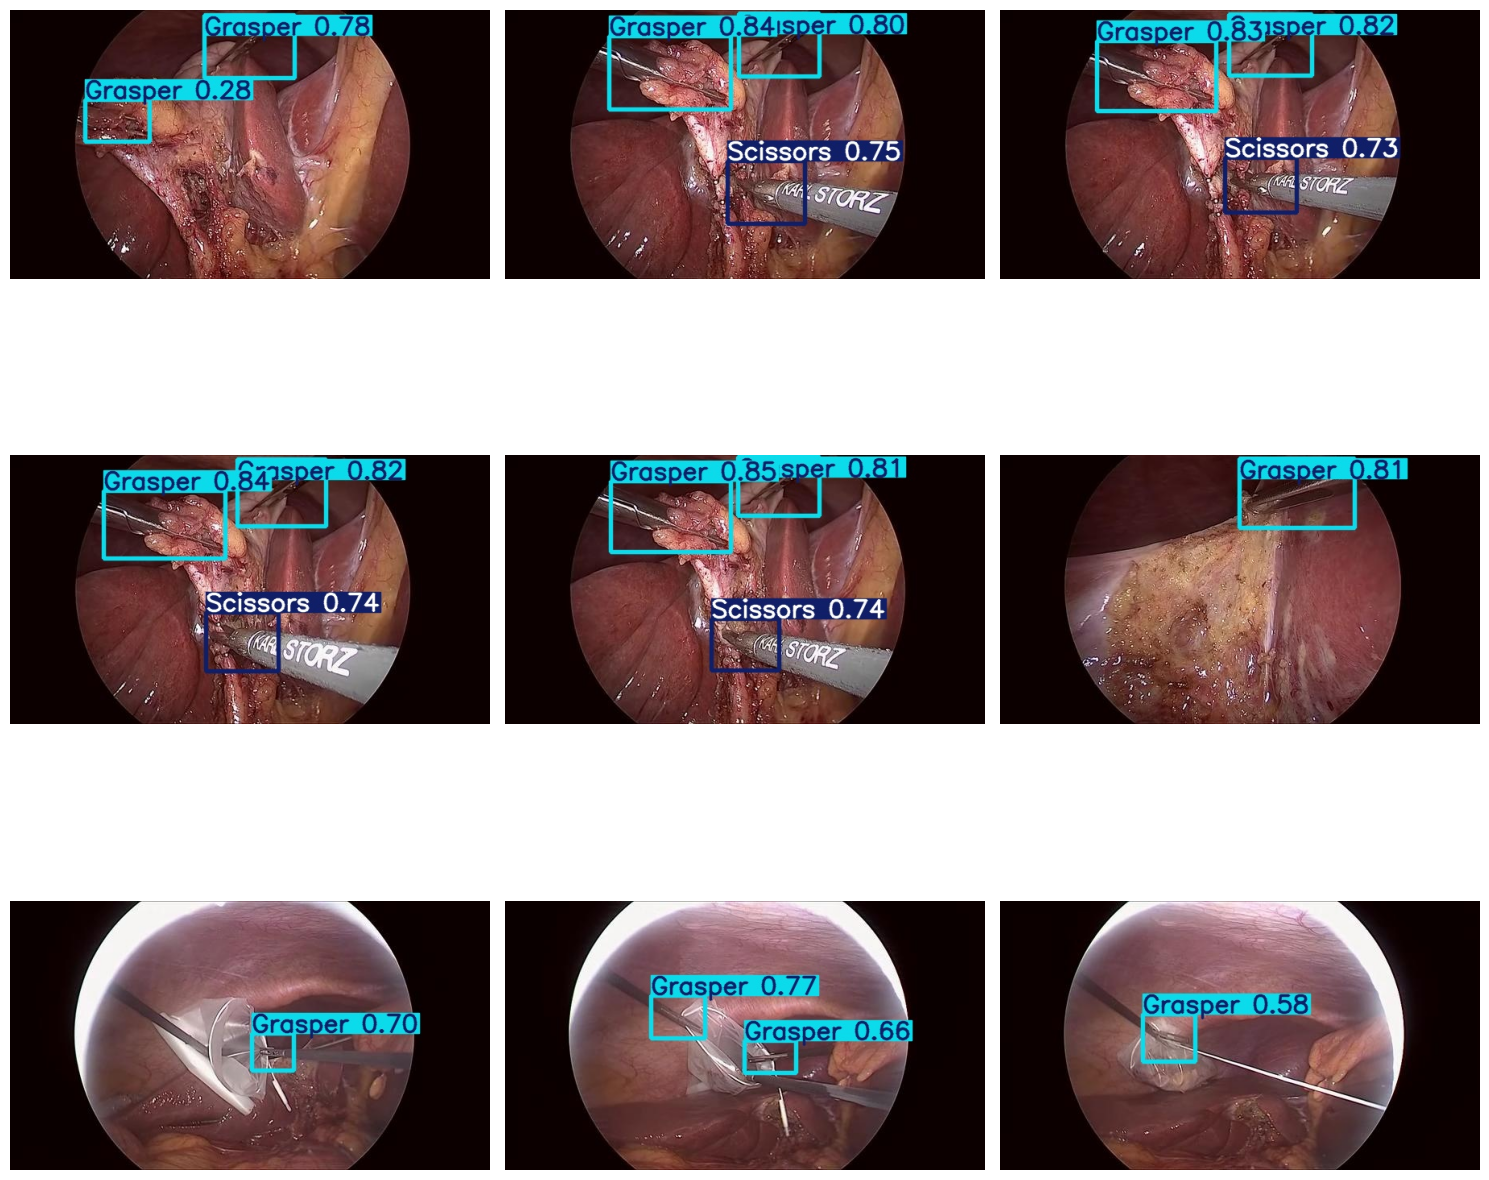

In [44]:
from glob import glob
import matplotlib.pyplot as plt
from PIL import Image

predictions_balanced = sorted(glob("/content/runs/detect/predict_balanced/*.jpg"))[:9]

plt.figure(figsize=(15, 15))

for i, img_path in enumerate(predictions_balanced):
    img = Image.open(img_path)
    plt.subplot(3, 3, i + 1)
    plt.imshow(img)
    plt.axis("off")

plt.tight_layout()
plt.show()

## 7. Comparision


In [45]:
CLASS_NAMES_LIST = ['Bipolar', 'Grasper', 'Hook', 'Irrigator', 'Scissors']

baseline_per_class = metrics.box.maps
balanced_per_class = metrics_balanced.box.maps

print(f"{'Class':10} {'Baseline mAP50-95':>18} {'Balanced mAP50-95':>18} {'Delta':>10}")
for i, name in enumerate(CLASS_NAMES_LIST):
    b = baseline_per_class[i]
    bal = balanced_per_class[i]
    print(f"{name:10} {b:18.4f} {bal:18.4f} {bal - b:10.4f}")

print()
print(f"{'Overall mAP50':10}: baseline={metrics.box.map50:.4f}  balanced={metrics_balanced.box.map50:.4f}")
print(f"{'Overall mAP50-95':10}: baseline={metrics.box.map:.4f}  balanced={metrics_balanced.box.map:.4f}")

Class       Baseline mAP50-95  Balanced mAP50-95      Delta
Bipolar                0.5672             0.5809     0.0137
Grasper                0.5254             0.5337     0.0082
Hook                   0.7369             0.7093    -0.0276
Irrigator              0.5003             0.4504    -0.0499
Scissors               0.5828             0.6076     0.0248

Overall mAP50: baseline=0.9604  balanced=0.9451
Overall mAP50-95: baseline=0.5825  balanced=0.5764
